# Day 9 - SHAP explainability

Explain the frozen Day 8 provisional XGBoost candidate. This is an explanatory analysis: no model fitting, tuning, feature changes, calibration or final threshold selection. Random Forest remains a challenger for fixed-capacity targeting. **TEST stays sealed.**

Run from the repository root or `notebooks/` with the project virtual environment. The notebook regenerates the tables, figures and narrative under `reports/` through reusable functions in `src/explainability.py`. No raw player rows or identifiers are displayed.

In [1]:
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/explainability.py').is_file(), 'Run within the project repository.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.explainability import (
    load_candidate, compute_analysis, export_analysis, validate_shap_matrix,
    validate_local_export, summary_markdown,
)
from src.features import PREDICTOR_COLUMNS


## 1. Load the frozen pipeline and reproduce validation metrics

`load_candidate` verifies the Day 8 data fingerprint and selected hyperparameters, loads `models/xgboost_model.joblib`, and reuses the original temporal split. It constructs validation only and discards the loaded panel before prediction. No training fallback is permitted. PR-AUC here means average precision.

In [2]:
analysis = load_candidate(ROOT)
display(pd.DataFrame([analysis['metrics']]))
print('Saved model loaded unchanged. Validation metrics match the Day 8 artifact.')

,roc_auc,average_precision
0,0.746382,0.563016


Saved model loaded unchanged. Validation metrics match the Day 8 artifact.


## 2. Seeded validation sample and TreeExplainer

Uniformly sample up to 1,000 validation observations without replacement, seed 42. Explain the fitted classifier after the existing preprocessing. The tree-path-dependent reference uses training path counts stored in the model; there is no new background dataset. SHAP values are in **log-odds**. The sigmoid of the base value plus summed contributions reconstructs the predicted probability.

The functions reject test, training, embargo, empty and mixed-date frames before transformation or explanation.

In [3]:
analysis = compute_analysis(analysis, size=1000)
validate_shap_matrix(analysis['explanation'].values, analysis['matrix'], analysis['mapping'])
print(f"Validation rows: {len(analysis['validation']):,}; SHAP sample: {len(analysis['sample']):,}")
print(f"SHAP matrix: {analysis['explanation'].values.shape}; all values finite")
print('Additivity and probability reconstruction passed for every sampled row.')

Validation rows: 2,184; SHAP sample: 1,000
SHAP matrix: (1000, 112); all values finite
Additivity and probability reconstruction passed for every sampled row.


## 3. Exact transformed feature names

The fitted transformer's output defines column order. The mapping preserves numeric columns, learned numeric missingness flags, and Country/Language/Gender one-hot levels. It records readable labels, raw source features and semantic groups. Metadata and target are rejected.

In [4]:
mapping = analysis['mapping']
assert set(mapping.source_feature).issubset(PREDICTOR_COLUMNS)
assert len(mapping) == analysis['matrix'].shape[1]
display(mapping)
# Persist only aggregate explanations, anonymous local scores and column metadata.
export_analysis(analysis)
report = summary_markdown(analysis)
def show_section(title):
    section = report.split('## ' + title + '\n', 1)[1].split('\n## ', 1)[0]
    display(Markdown(section))
def show_figure(filename):
    display(Image(filename=str(ROOT / 'reports/figures' / filename)))

,position,transformed_feature,feature,source_feature,feature_group
0,0,numeric__active_days_30d,active_days_30d,active_days_30d,activity
1,1,numeric__bets_30d,bets_30d,bets_30d,betting volume
2,2,numeric__active_days_14d,active_days_14d,active_days_14d,activity
3,3,numeric__bets_14d,bets_14d,bets_14d,betting volume
4,4,numeric__active_days_7d,active_days_7d,active_days_7d,activity
...,...,...,...,...,...
107,107,categorical__Language_18,Language = 18,Language,demographics
108,108,categorical__Language_19,Language = 19,Language,demographics
109,109,categorical__Language_20,Language = 20,Language,demographics
110,110,categorical__Gender_0,Gender = 0,Gender,demographics


## 4. Global SHAP importance


| feature | mean_abs_shap | feature_group |
| --- | --- | --- |
| days_since_last_active_bet | 0.3443 | recency |
| days_since_first_casino_activity | 0.2446 | lifecycle |
| winnings_7d | 0.2139 | monetary |
| active_days_30d | 0.1979 | activity |
| net_loss_30d | 0.1019 | monetary |
| net_loss_7d | 0.0698 | monetary |
| winnings_14d | 0.0632 | monetary |
| days_since_first_pay | 0.0609 | lifecycle |
| active_days_recent15 | 0.0594 | trend |
| active_days_early15 | 0.0522 | trend |
| mean_gap_between_active_days_30d | 0.0501 | activity |
| bets_30d | 0.0413 | betting volume |
| winnings_30d | 0.0376 | monetary |
| Language = 2 | 0.0367 | demographics |
| stake_recent15 | 0.0362 | trend |
| max_daily_stake_30d | 0.0318 | monetary |
| avg_bets_per_active_day_30d | 0.0311 | betting volume |
| active_days_7d_share | 0.0303 | trend |
| avg_bets_per_active_day_7d | 0.0267 | betting volume |
| days_since_registration | 0.0259 | lifecycle |

The global table ranks transformed columns; category levels and missingness flags remain distinct. Red in the beeswarm denotes a higher transformed value, blue a lower value. For dummy columns these mean present/absent, and for missingness flags they mean missing/not missing. Numeric color values after preprocessing include median imputations.


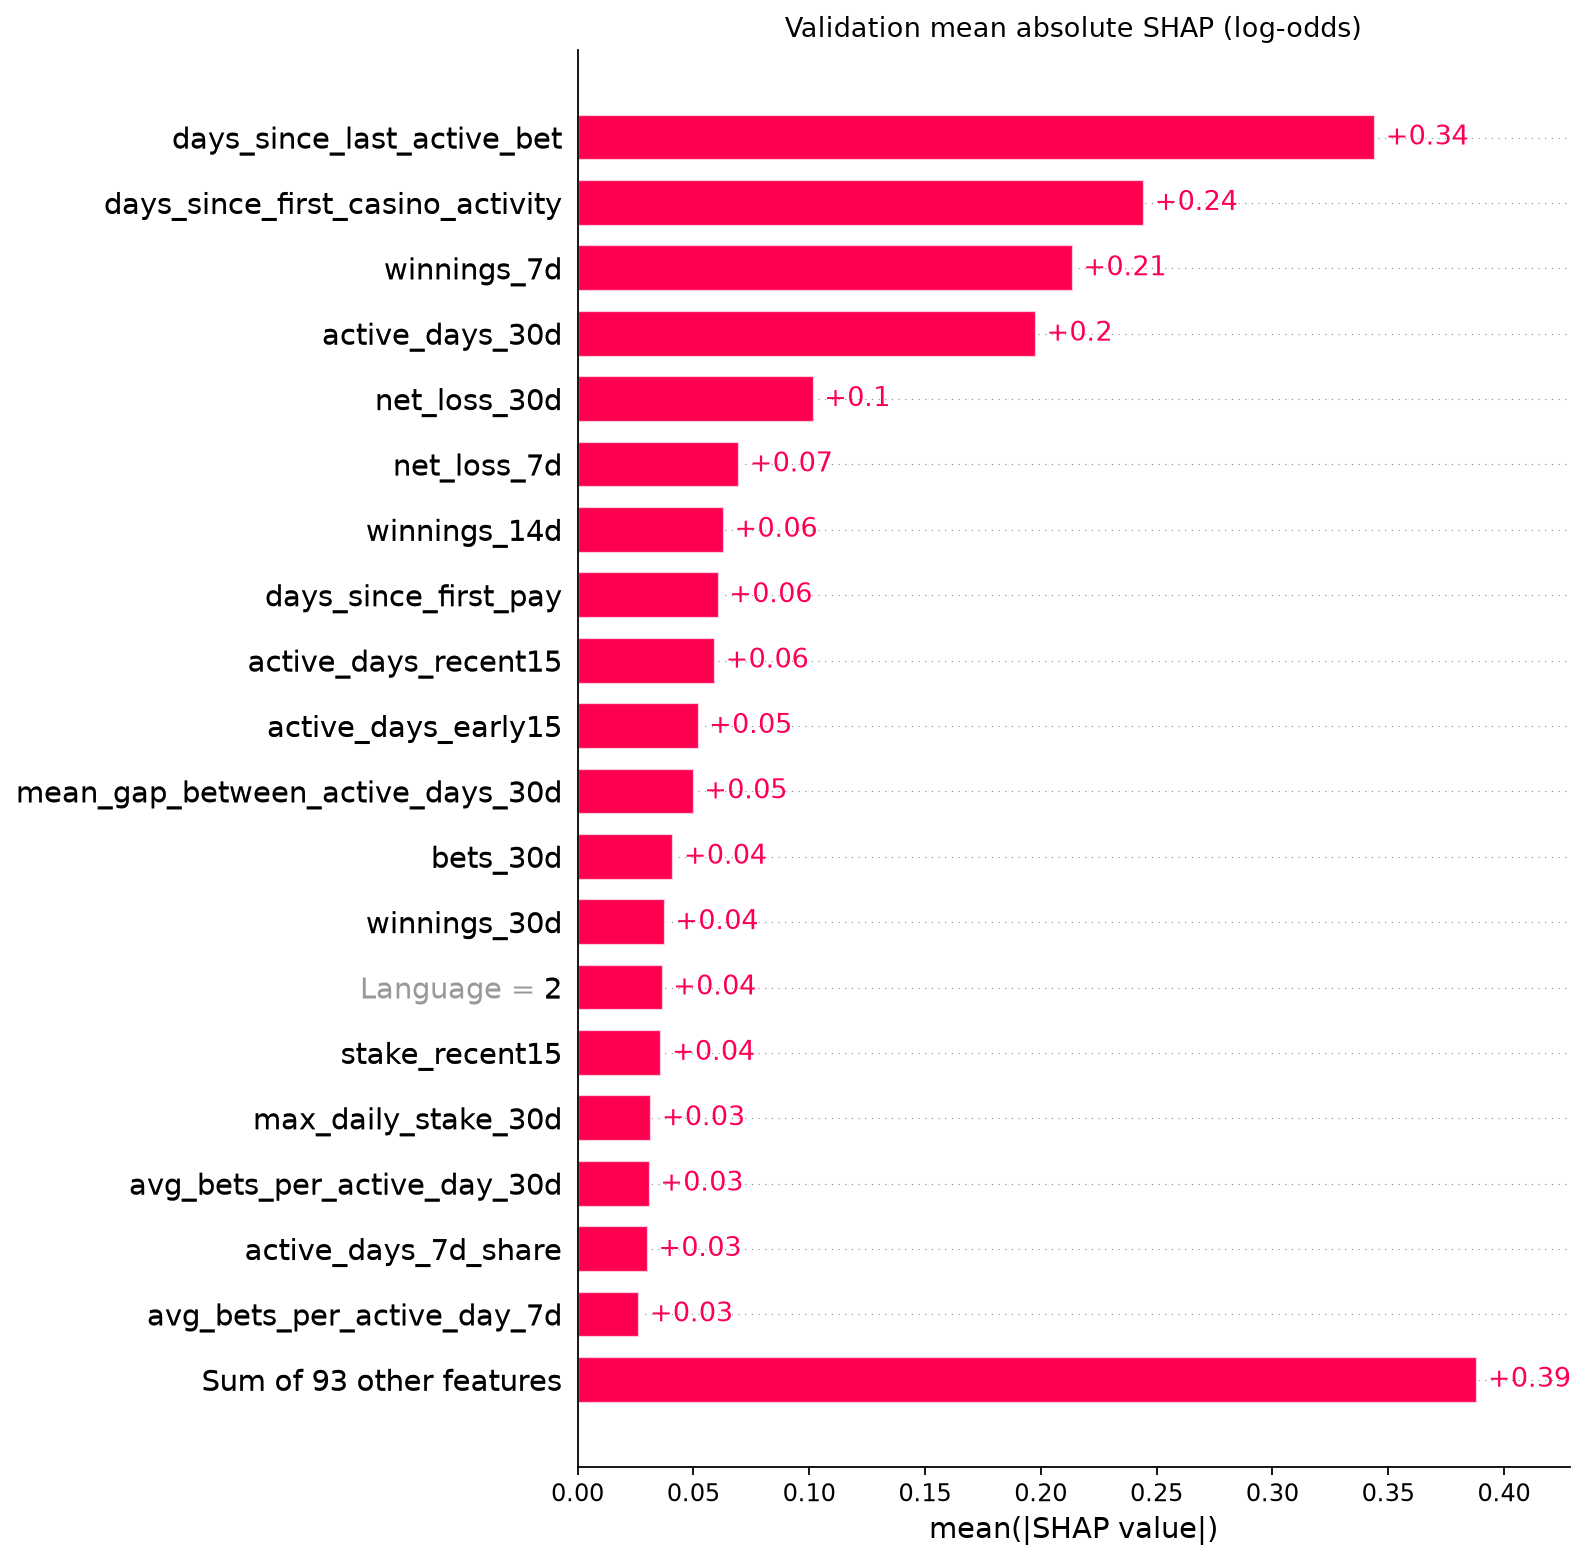

In [5]:
show_section('Global explanation')
show_figure('shap_global_bar.png')

## 5. Beeswarm summary

High transformed values are red, low values blue. Points to the right push toward extended inactivity; points to the left push away. Dummy colors mean category present/absent; missing-indicator colors mean missing/not missing. These are model associations, not causal effects.

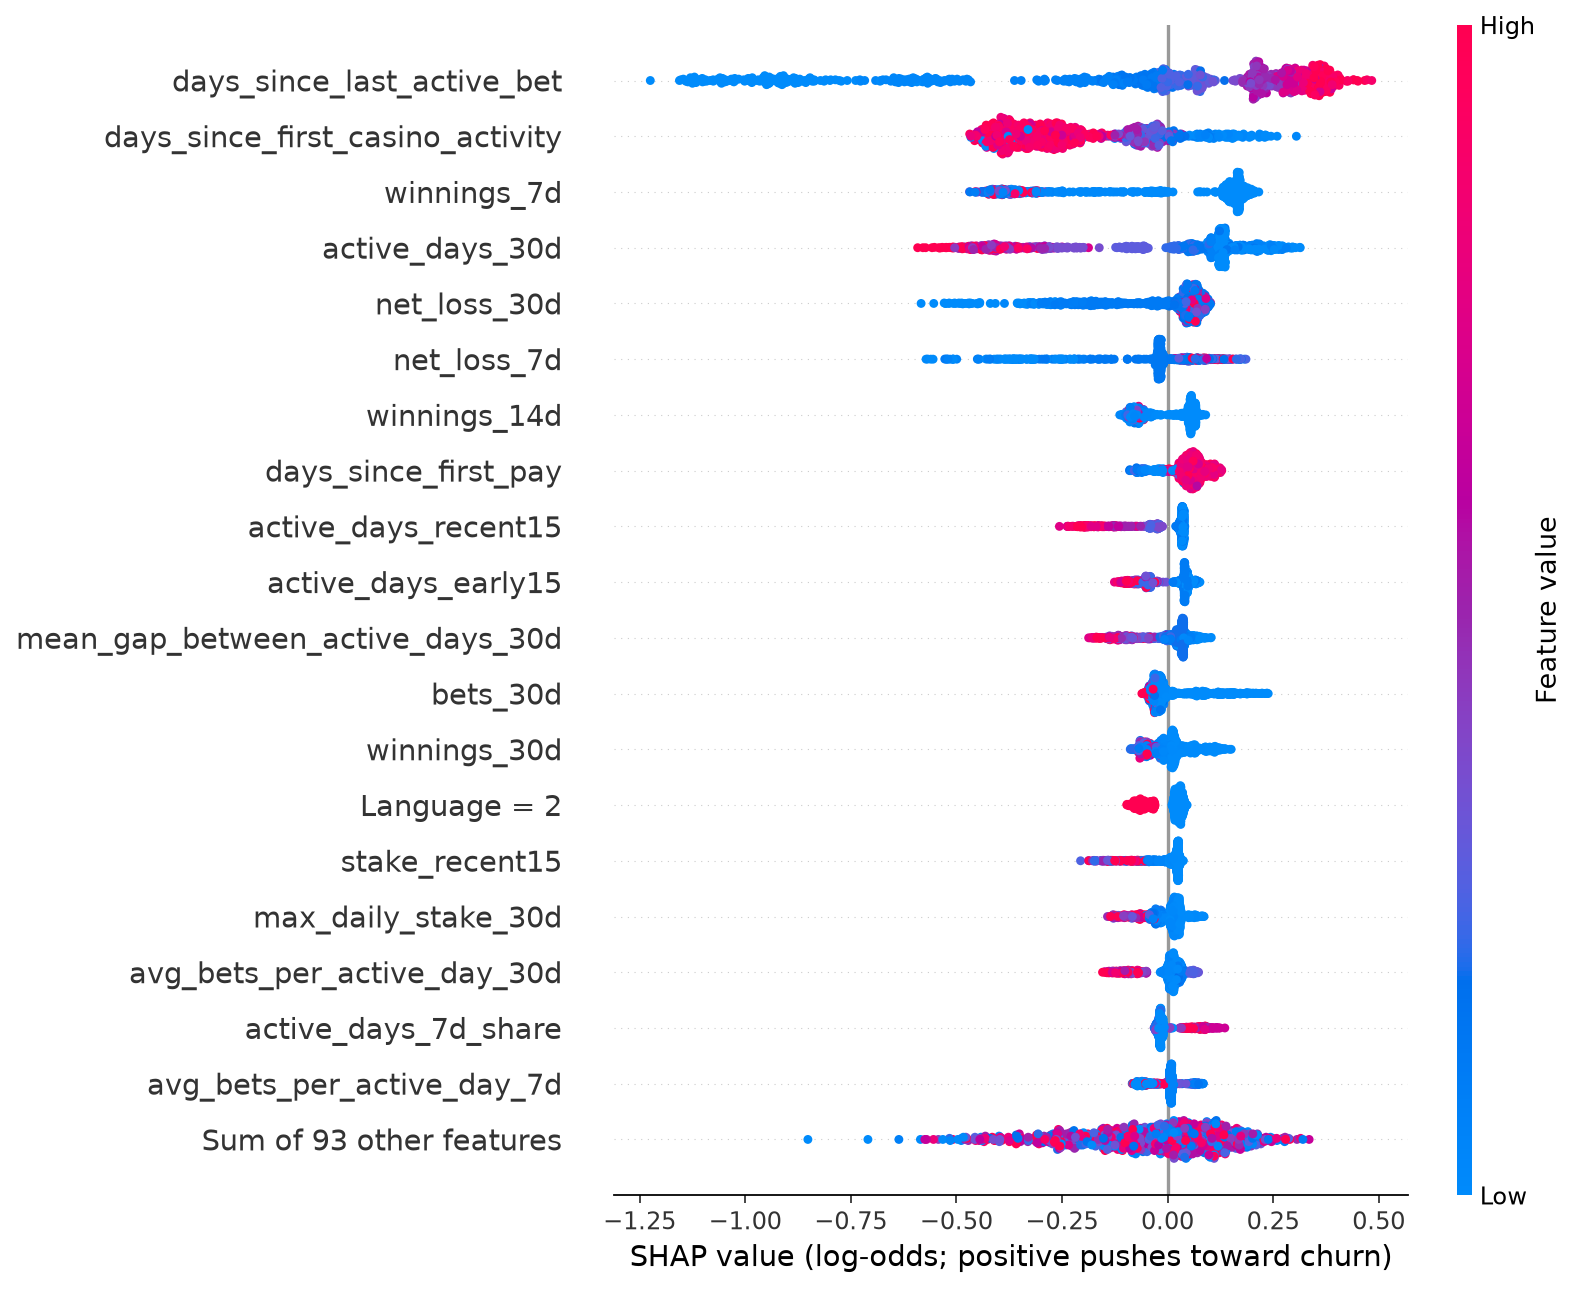

In [6]:
show_figure('shap_summary_beeswarm.png')

## 6. Dependence and nonlinear patterns

Use the five requested continuous variables only when they rank within the top 20 raw-source SHAP features. Scatter colors examine plausible interactions; color separation alone does not prove an interaction. Monetary axes use a signed log scale and retain finite extremes. Quantile-bin summaries are descriptive, not selected thresholds.


- **days_since_last_active_bet**: low observed bin [0, 1] (n=219) has mean SHAP -0.831; high bin [22, 29] (n=167) has +0.366 log-odds. Higher values have higher average contributions in this low/high comparison. Bin means are monotonic across this sample, but this does not establish a globally monotonic response.
- **active_days_30d**: low observed bin [1, 2] (n=502) has mean SHAP +0.154; high bin [9, 30] (n=158) has -0.421 log-odds. Higher values have lower average contributions in this low/high comparison. Bin means are monotonic across this sample, but this does not establish a globally monotonic response.
- **winnings_7d**: low observed bin [0, 44.6] (n=667) has mean SHAP +0.147; high bin [656, 5.72e+04] (n=167) has -0.384 log-odds. Higher values have lower average contributions in this low/high comparison. Bin means are monotonic across this sample, but this does not establish a globally monotonic response.
- **max_daily_stake_30d**: low observed bin [0, 20] (n=170) has mean SHAP +0.025; high bin [2.61e+03, 1.01e+05] (n=167) has -0.081 log-odds. Higher values have lower average contributions in this low/high comparison. Intermediate bin means reverse direction: the observed pattern is nonlinear/nonmonotonic.
- **days_since_first_casino_activity**: low observed bin [0, 149] (n=168) has mean SHAP +0.013; high bin [448, 484] (n=163) has -0.318 log-odds. Higher values have lower average contributions in this low/high comparison. Intermediate bin means reverse direction: the observed pattern is nonlinear/nonmonotonic.

These are marginal patterns in the observed validation sample, affected by other predictors and missingness. Quantile edges are descriptive bins, not learned operational thresholds. The dependence plots retain all finite values (monetary axes use a signed logarithmic scale); no cutoff or causal effect is inferred. Rows with a missing plotted value or color are excluded from that scatter; bin summaries separately record missing feature values.


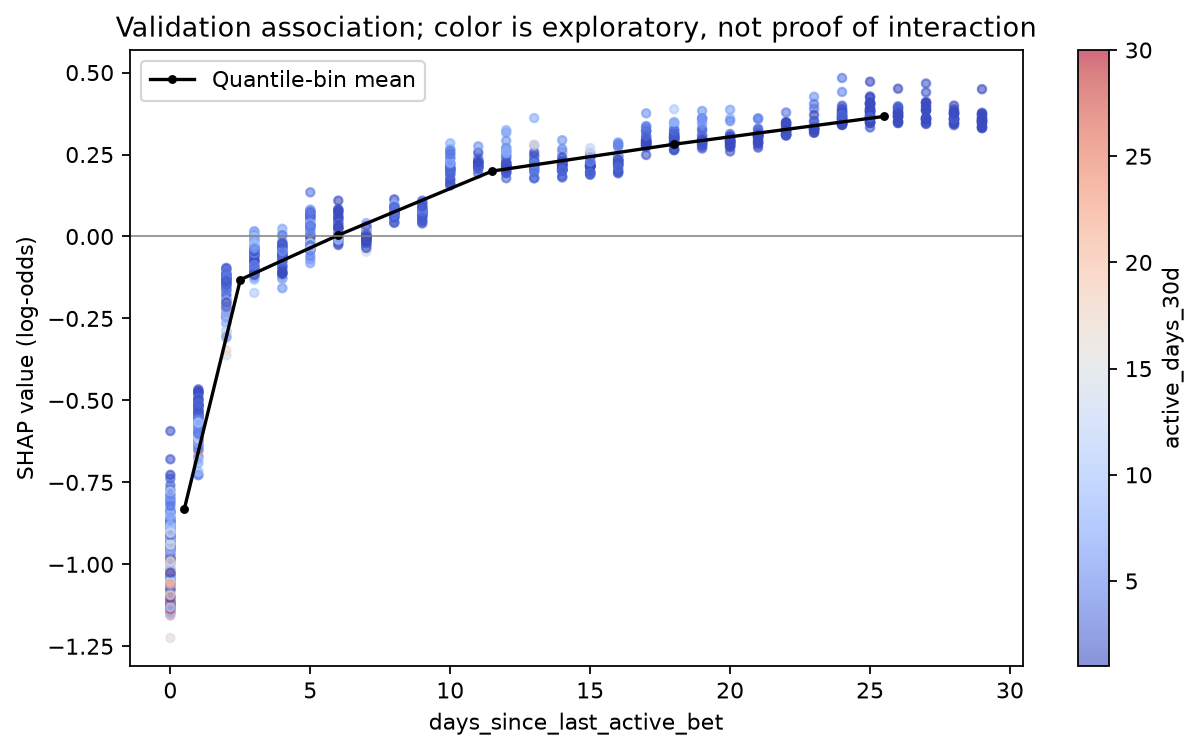

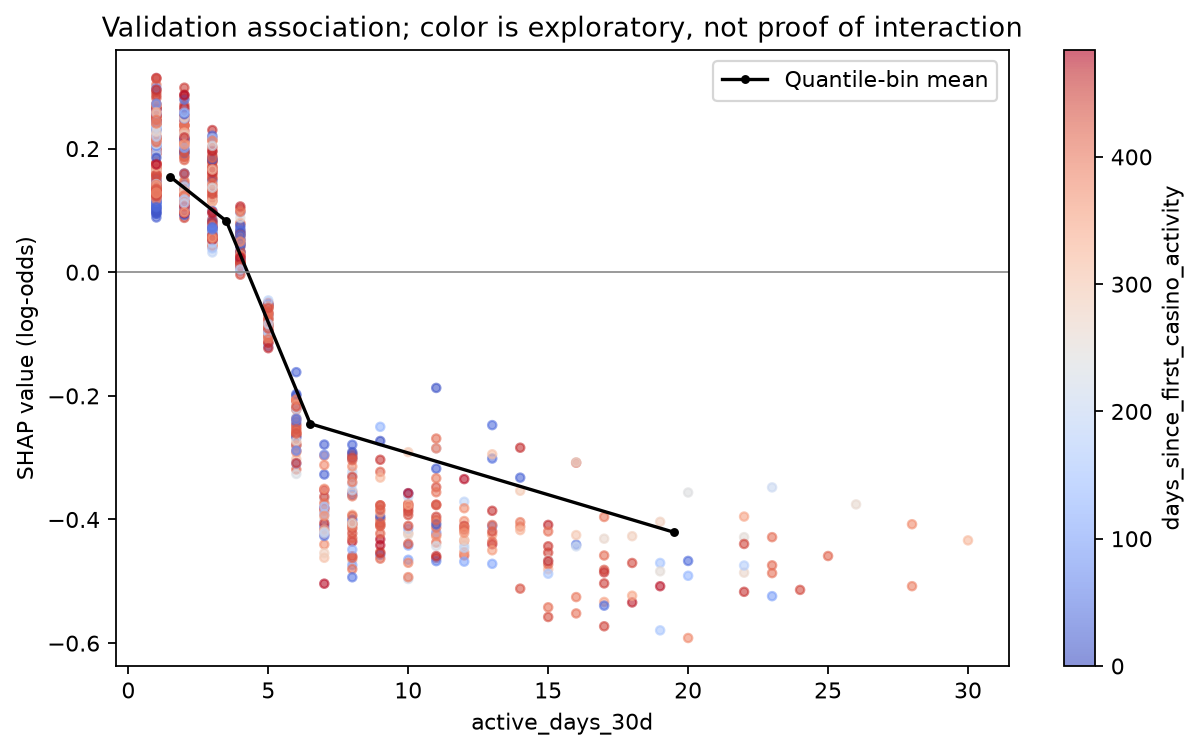

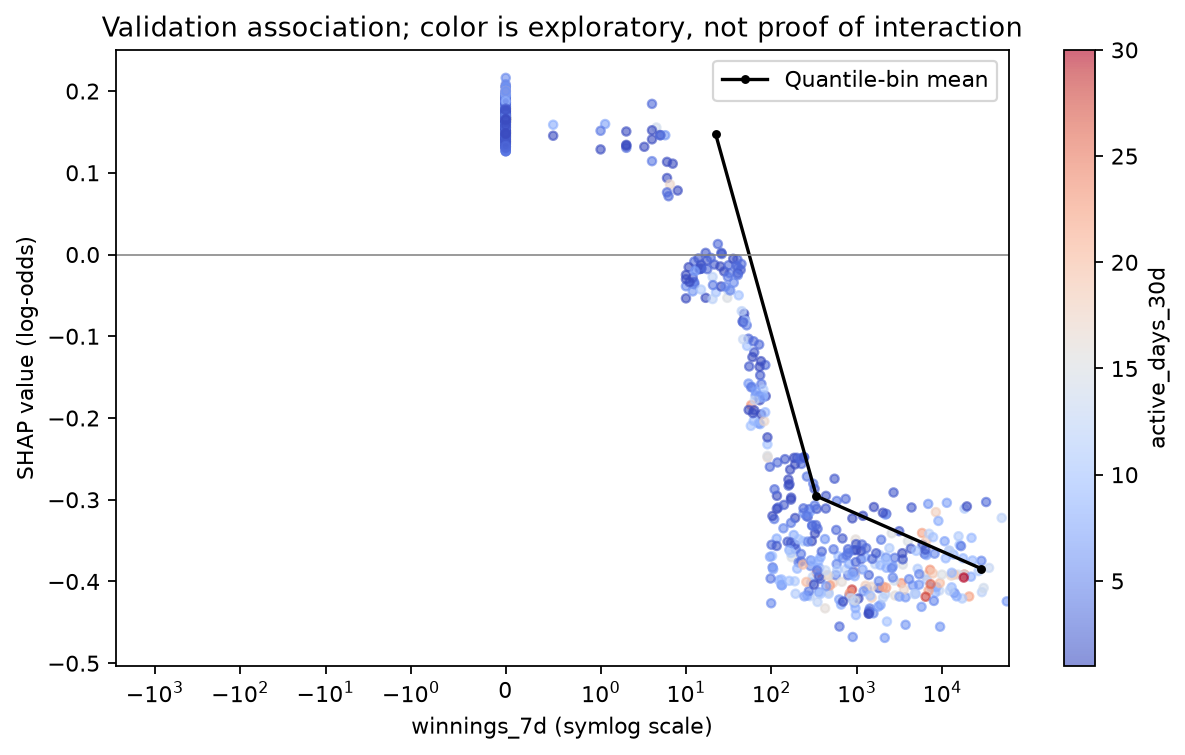

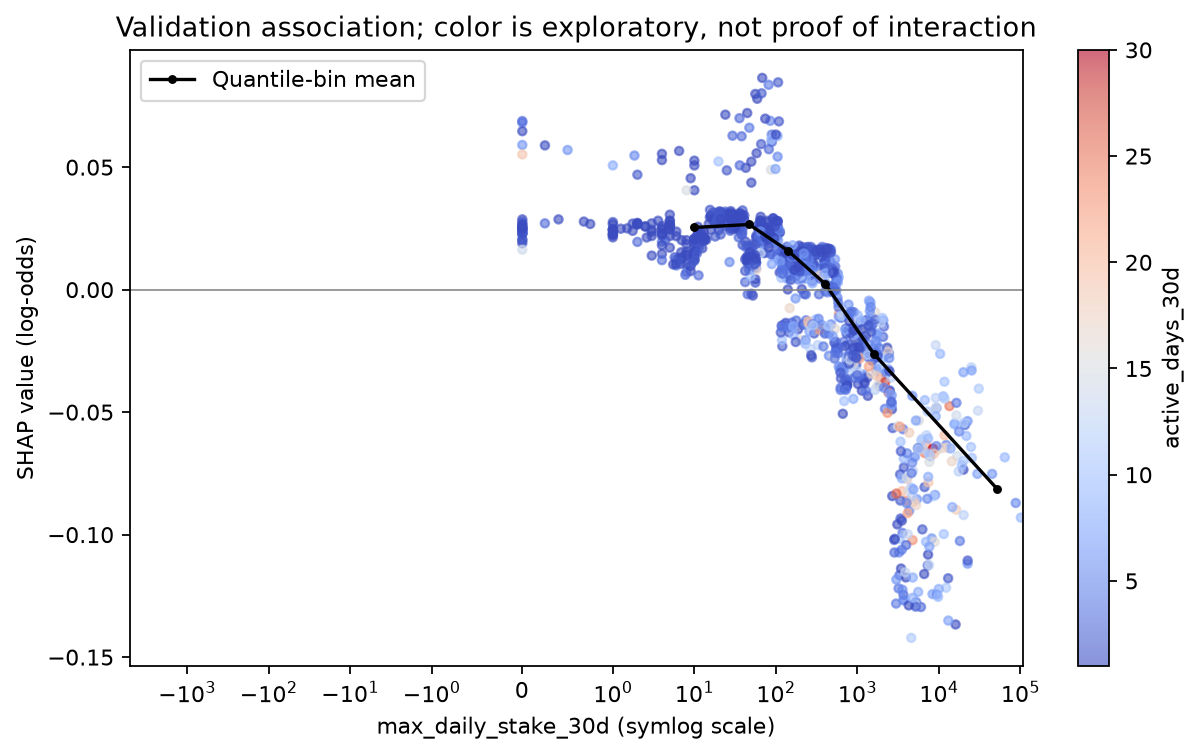

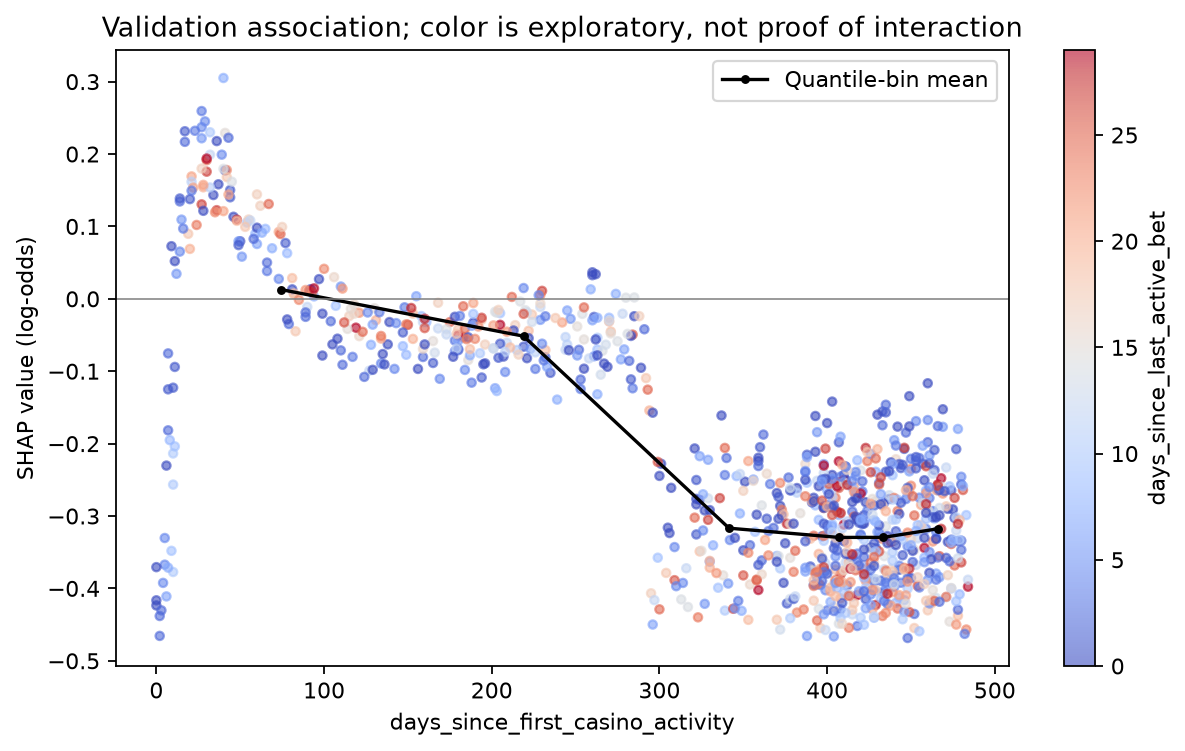

,feature,low,high,n,mean_shap,median_shap,missing
0,days_since_last_active_bet,0.00,1.0000,219,-0.830804,-0.885354,False
1,days_since_last_active_bet,2.00,3.0000,119,-0.131675,-0.122469,False
2,days_since_last_active_bet,4.00,8.0000,175,0.004134,0.001589,False
3,days_since_last_active_bet,9.00,14.0000,154,0.199532,0.213075,False
4,days_since_last_active_bet,15.00,21.0000,166,0.281410,0.287146,False
5,days_since_last_active_bet,22.00,29.0000,167,0.366292,0.361567,False
6,active_days_30d,1.00,2.0000,502,0.154272,0.130843,False
7,active_days_30d,3.00,4.0000,181,0.082734,0.063057,False
8,active_days_30d,5.00,8.0000,159,-0.245133,-0.264566,False
9,active_days_30d,9.00,30.0000,158,-0.420701,-0.423342,False


In [7]:
show_section('Direction and nonlinear patterns')
for feature in analysis['features']:
    show_figure('shap_dependence_' + feature + '.png')
display(analysis['bins'])

## 7. Targeted fitted-model interaction diagnostics

Avoid a full feature-by-feature SHAP interaction tensor. Use four prespecified feature pairs and small 2x2 contrasts in the fitted model's log-odds response. These are **not exact SHAP interaction values**. Correlated and derived predictors remain fixed, so synthetic combinations can be inconsistent or outside observed support.

In [8]:
show_section('Targeted interaction diagnostics')


| feature_1 | feature_2 | first_low | first_high | second_low | second_high | mean_mixed_margin | mean_abs_mixed_margin | fraction_nonzero | n |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| days_since_last_active_bet | active_days_30d | 2.0000 | 18.0000 | 1.0000 | 6.0000 | 0.2877 | 0.2877 | 1.0000 | 1000 |
| days_since_last_active_bet | bets_30d | 2.0000 | 18.0000 | 10.0000 | 297.2500 | -0.0000 | 0.0000 | 0.0000 | 1000 |
| active_days_30d | days_since_first_casino_activity | 1.0000 | 6.0000 | 218.0000 | 432.5000 | -0.0216 | 0.0220 | 1.0000 | 1000 |
| winnings_7d | active_days_30d | 0.0000 | 171.1465 | 1.0000 | 6.0000 | -0.1071 | 0.1073 | 1.0000 | 1000 |

These are small 2x2 fitted log-odds contrasts at each feature's validation Q25/Q75, averaged over validation sample contexts. A mixed difference is f(high,high) - f(high,low) - f(low,high) + f(low,low). A nonzero contrast supports non-additivity of the fitted function at those synthetic points; a near-zero contrast does not rule out interactions elsewhere. Positive mean contrast means the joint high/high log-odds response exceeds the sum of the two separate changes. No full interaction matrix or SHAP interaction values were computed. Dependence-plot color alone does not prove an interaction. Holding correlated and derived predictors fixed can create inconsistent/off-support combinations, so these diagnostics do not establish real-player or causal effects.


## 8. Anonymous local explanations

At diagnostic threshold 0.50, select the sampled example nearest the within-cell median score for each of TP, FP, TN and FN. This is illustrative, not population representativeness. Exported waterfalls omit raw predictor values, row indices, dates and player identifiers.


One example nearest to the within-cell median predicted probability is selected for each outcome within the SHAP sample. This is an illustrative selection rule, not a claim of population representativeness. Raw player records, identifiers, row indices, dates and local predictor values are omitted from exports. Waterfalls show anonymous feature contributions in log-odds.

| case | outcome | probability | actual | increasing_risk | decreasing_risk |
| --- | --- | --- | --- | --- | --- |
| Validation Case A | TP | 0.5729 | 1 | days_since_last_active_bet (+0.343 log-odds); winnings_7d (+0.166 log-odds); active_days_30d (+0.129 log-odds) | days_since_first_casino_activity (-0.291 log-odds); days_since_registration (-0.026 log-odds); net_loss_7d (-0.024 log-odds) |
| Validation Case B | FP | 0.5560 | 0 | days_since_last_active_bet (+0.210 log-odds); winnings_7d (+0.151 log-odds); bets_30d (+0.149 log-odds) | days_since_first_casino_activity (-0.241 log-odds); net_loss_30d (-0.152 log-odds); avg_stake_per_bet_30d (-0.045 log-odds) |
| Validation Case C | TN | 0.1996 | 0 | active_days_30d (+0.099 log-odds); net_loss_30d (+0.089 log-odds); days_since_first_pay (+0.061 log-odds) | days_since_first_casino_activity (-0.396 log-odds); winnings_7d (-0.360 log-odds); mean_gap_between_active_days_30d (-0.147 log-odds) |
| Validation Case D | FN | 0.3738 | 1 | active_days_30d (+0.271 log-odds); net_loss_7d (+0.163 log-odds); days_since_first_pay (+0.087 log-odds) | days_since_last_active_bet (-0.727 log-odds); days_since_first_casino_activity (-0.224 log-odds); avg_bets_per_active_day_7d (-0.055 log-odds) |

The same risk-increasing associations can occur in both TP/FP cases, and risk-decreasing associations in both TN/FN cases: an explanation describes the score, not why the observed outcome occurred. The 0.50 diagnostic does not select a deployment threshold.


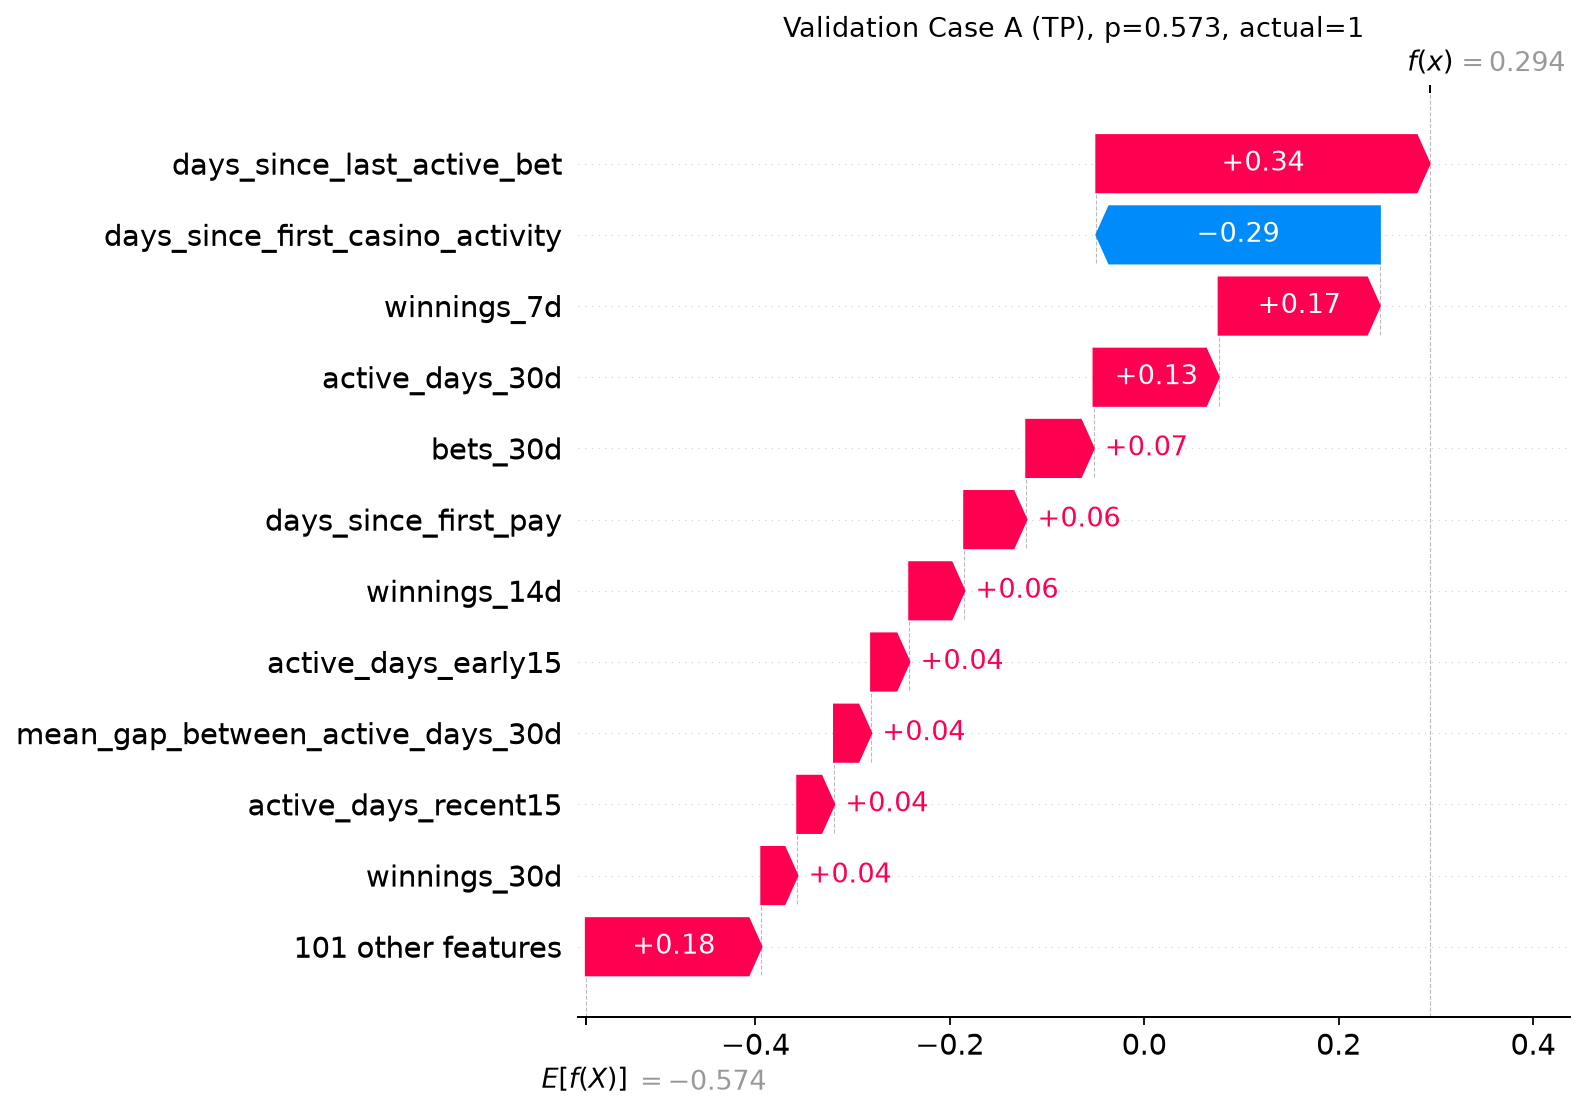

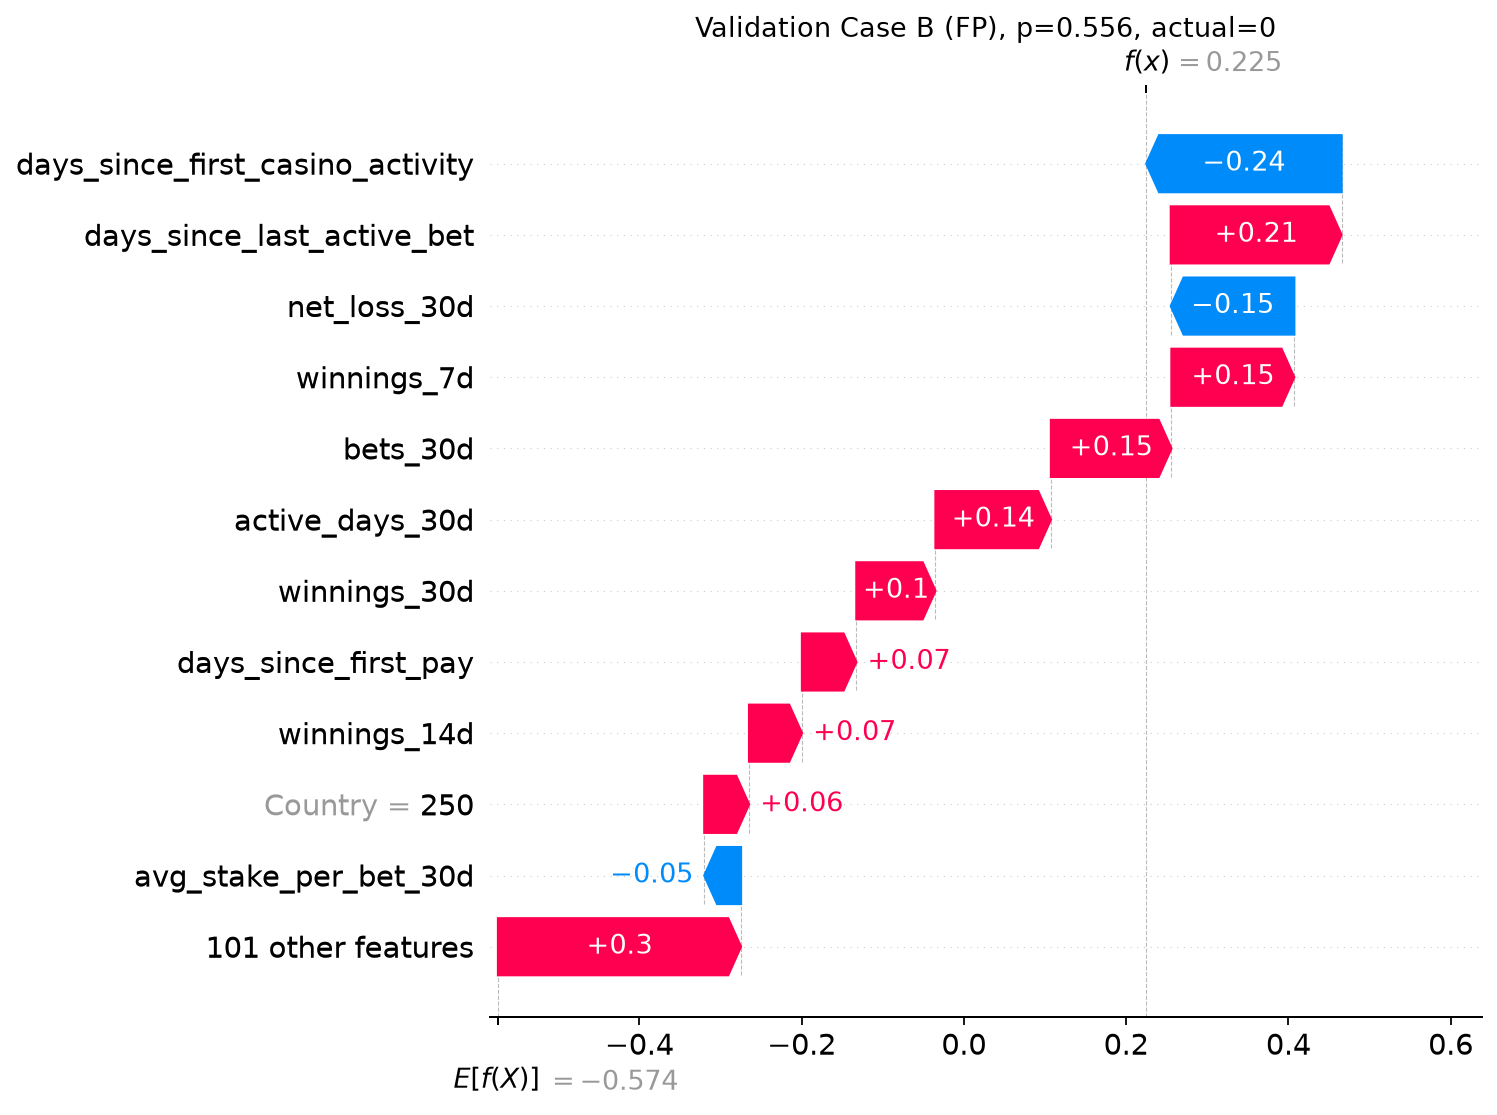

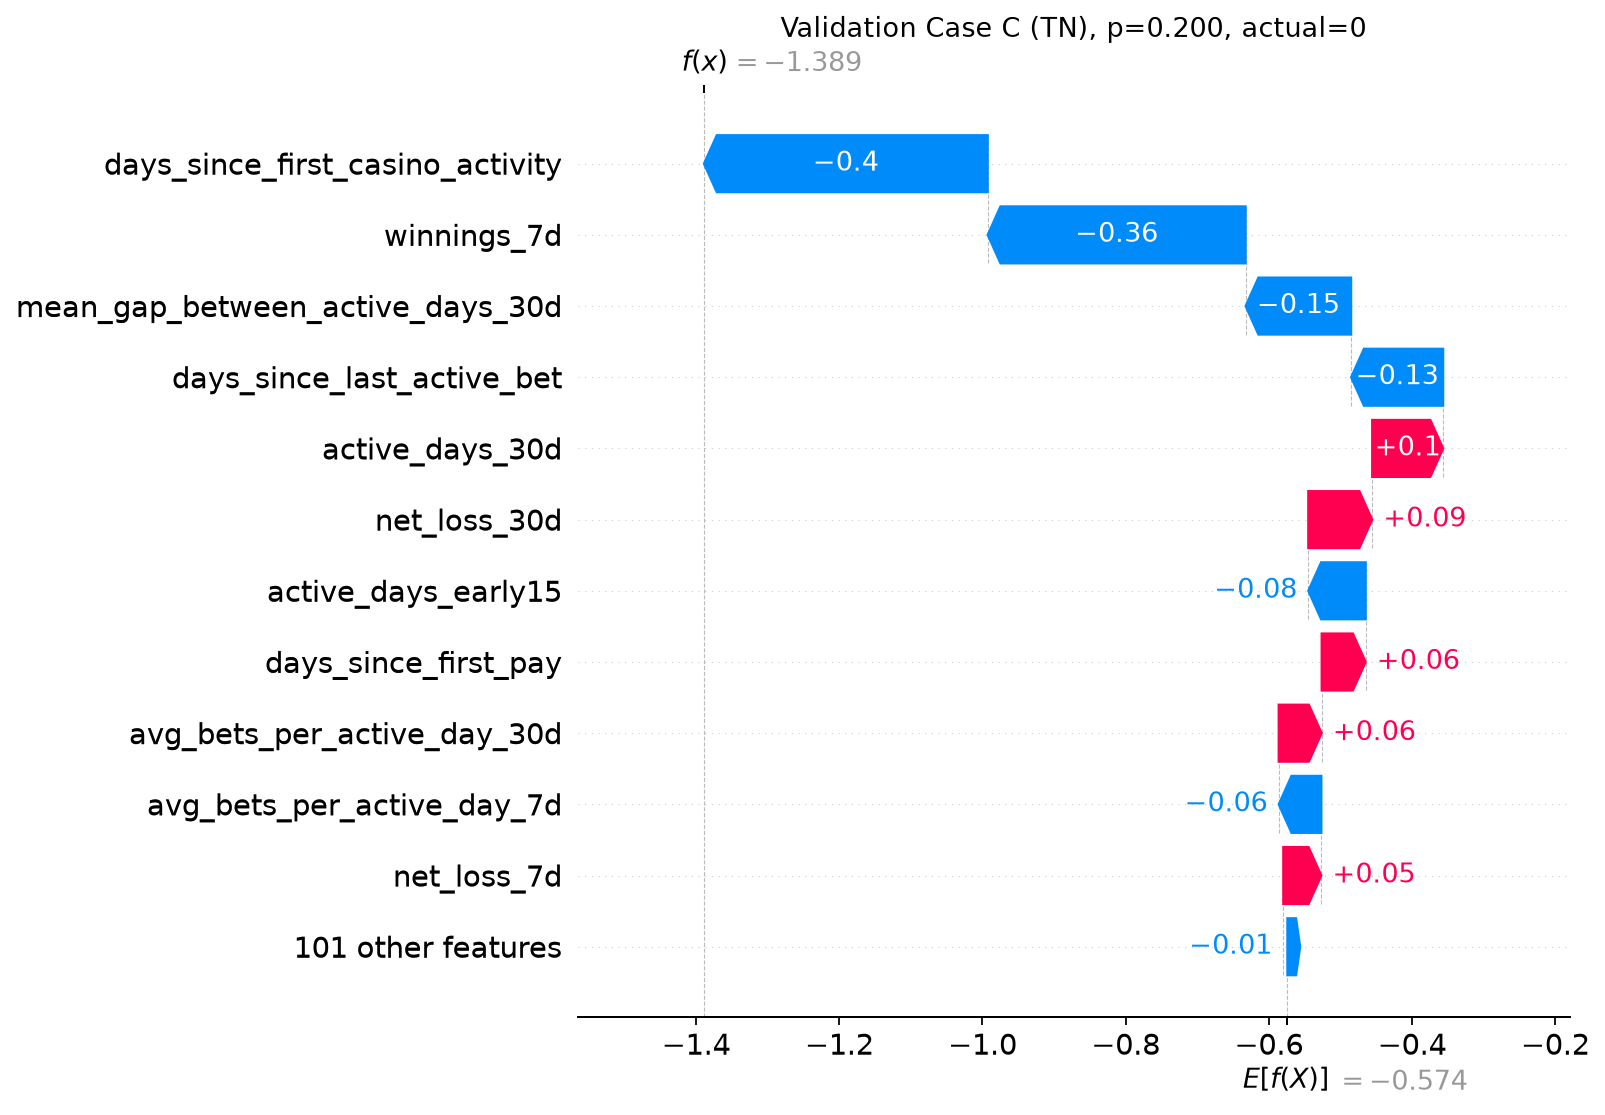

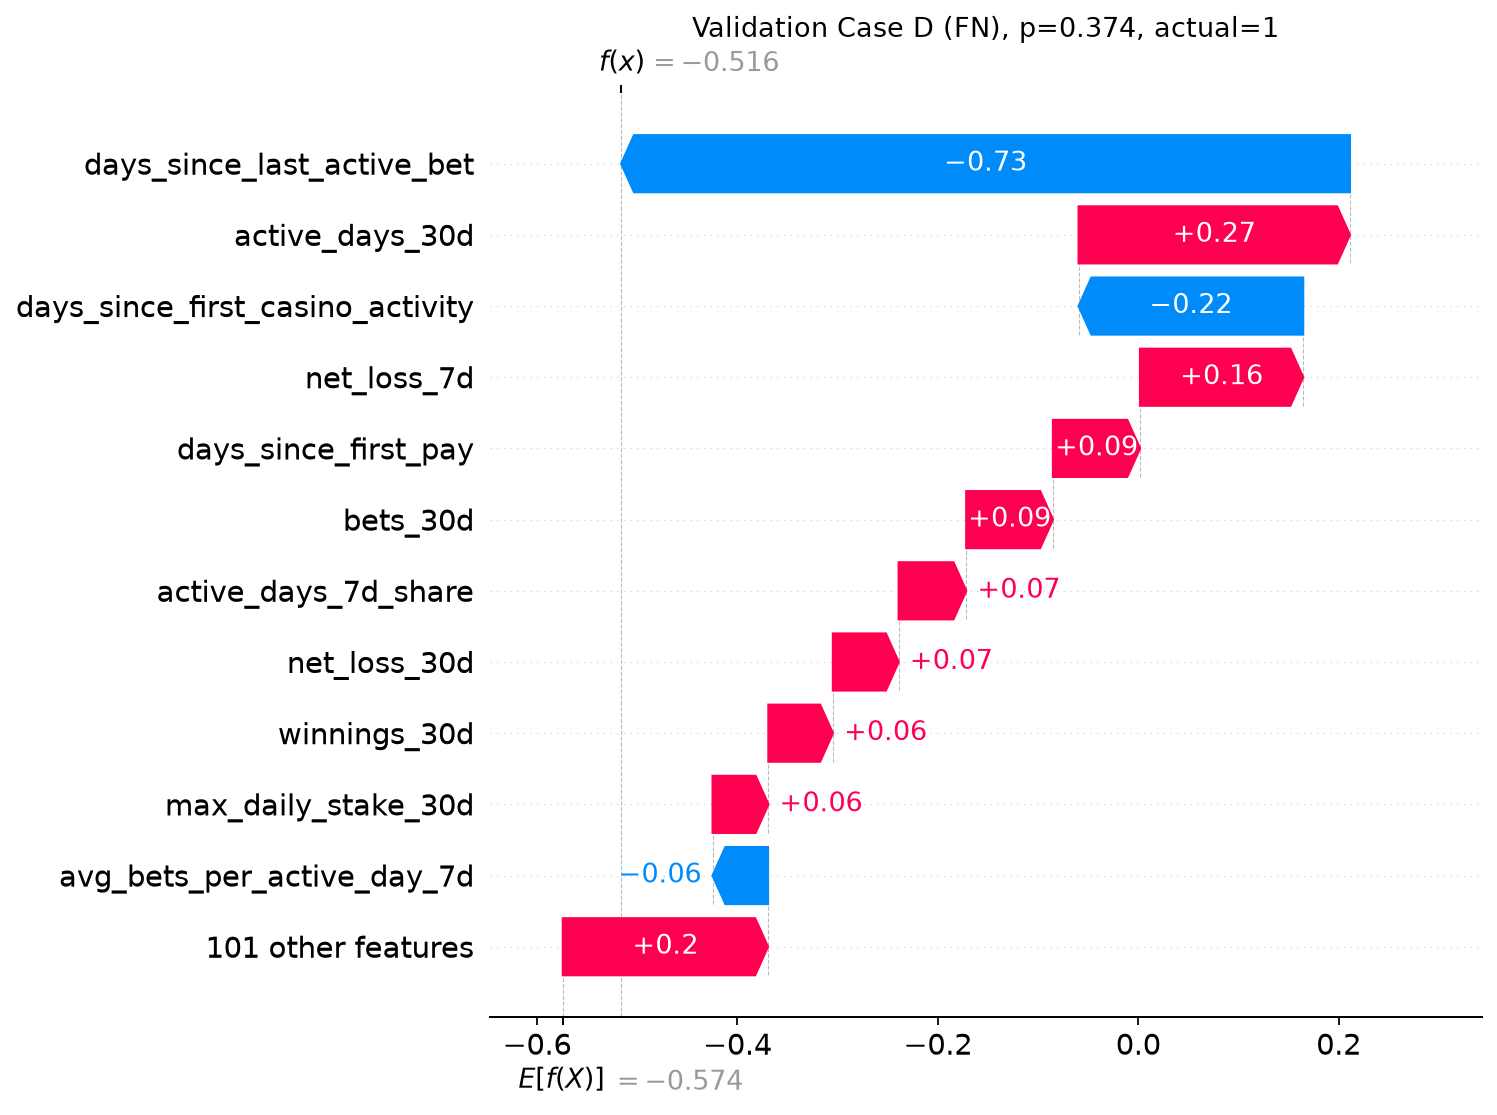

In [9]:
validate_local_export(analysis['cases'])
show_section('Local explanations (diagnostic threshold 0.50)')
for case in analysis['case_positions']:
    show_figure('shap_waterfall_case_' + case[-1].lower() + '.png')

## 9. Compare with Day 8 permutation importance

Compare at the **raw source-feature** level: first sum each row's signed dummy/indicator/continuous contributions for a source, then take its absolute value and average. This matches the raw input unit permuted before preprocessing. The exported transformed-column table and group table use different aggregation rules.

In [10]:
show_section('Consistency with Day 8 permutation importance')


| feature | shap_rank | permutation_rank | notes |
| --- | --- | --- | --- |
| days_since_last_active_bet | 1 | 1 | Both top 10 |
| days_since_first_casino_activity | 2 | 4 | Both top 10 |
| winnings_7d | 3 | 2 | Both top 10 |
| active_days_30d | 4 | 3 | Both top 10 |
| net_loss_30d | 5 | 15 | Different attribution/AP disruption; correlated features may redistribute importance |
| net_loss_7d | 6 | 45 | Different attribution/AP disruption; correlated features may redistribute importance |
| winnings_14d | 7 | 22 | Different attribution/AP disruption; correlated features may redistribute importance |
| days_since_first_pay | 8 | 6 | Both top 10 |
| active_days_recent15 | 9 | 8 | Both top 10 |
| active_days_early15 | 10 | 13 | Ranks within 5 positions |
| mean_gap_between_active_days_30d | 11 | 10 | Ranks within 5 positions |
| Language | 12 | 32 | Different attribution/AP disruption; correlated features may redistribute importance |
| bets_30d | 13 | 25 | Different attribution/AP disruption; correlated features may redistribute importance |
| winnings_30d | 14 | 16 | Ranks within 5 positions |
| stake_recent15 | 15 | 11 | Ranks within 5 positions |
| Country | 16 | 14 | Ranks within 5 positions |
| max_daily_stake_30d | 17 | 5 | Different attribution/AP disruption; correlated features may redistribute importance |
| avg_bets_per_active_day_30d | 18 | 44 | Different attribution/AP disruption; correlated features may redistribute importance |
| active_days_7d_share | 19 | 31 | Different attribution/AP disruption; correlated features may redistribute importance |
| avg_bets_per_active_day_7d | 20 | 20 | Ranks within 5 positions |

Top-10 overlap: 6/10; source-level Spearman rank correlation 0.626. The five earlier drivers have SHAP source ranks: days_since_last_active_bet 1, winnings_7d 3, active_days_30d 4, days_since_first_casino_activity 2, max_daily_stake_30d 17.

SHAP partly challenges the earlier ordering; inspect the source ranks above.

For comparability, signed SHAP contributions of every raw feature's descendants (including its missing indicator and category levels) are summed within each row, then absolute-valued and averaged. This differs from the transformed/group tables. Permutation importance measures full-validation average-precision loss after shuffling a raw predictor (five repeats); SHAP measures contribution magnitude in a 1,000-row sample. Correlated predictors can share SHAP credit; permutation can disrupt correlated structure, and nonlinear interactions redistribute contributions. Small negative AP drops reflect noise/redundancy, not protective effects. Neither ranking is absolute truth.


## 10. Executive feature-group view


| feature_group | mean_abs_shap | share |
| --- | --- | --- |
| monetary | 0.5993 | 0.2829 |
| recency | 0.3443 | 0.1625 |
| lifecycle | 0.3315 | 0.1565 |
| activity | 0.3013 | 0.1422 |
| trend | 0.2983 | 0.1408 |
| demographics | 0.1212 | 0.0572 |
| betting volume | 0.1197 | 0.0565 |
| missingness | 0.0030 | 0.0014 |

Group scores sum per-column mean absolute SHAP. They describe attribution mass, not explained variance or percentages of predicted risk. Correlated and larger groups can accumulate attribution; signed contributions can cancel within a row. Recent/early half-window predictors and change/share predictors are grouped as trend; missingness always has its own group.


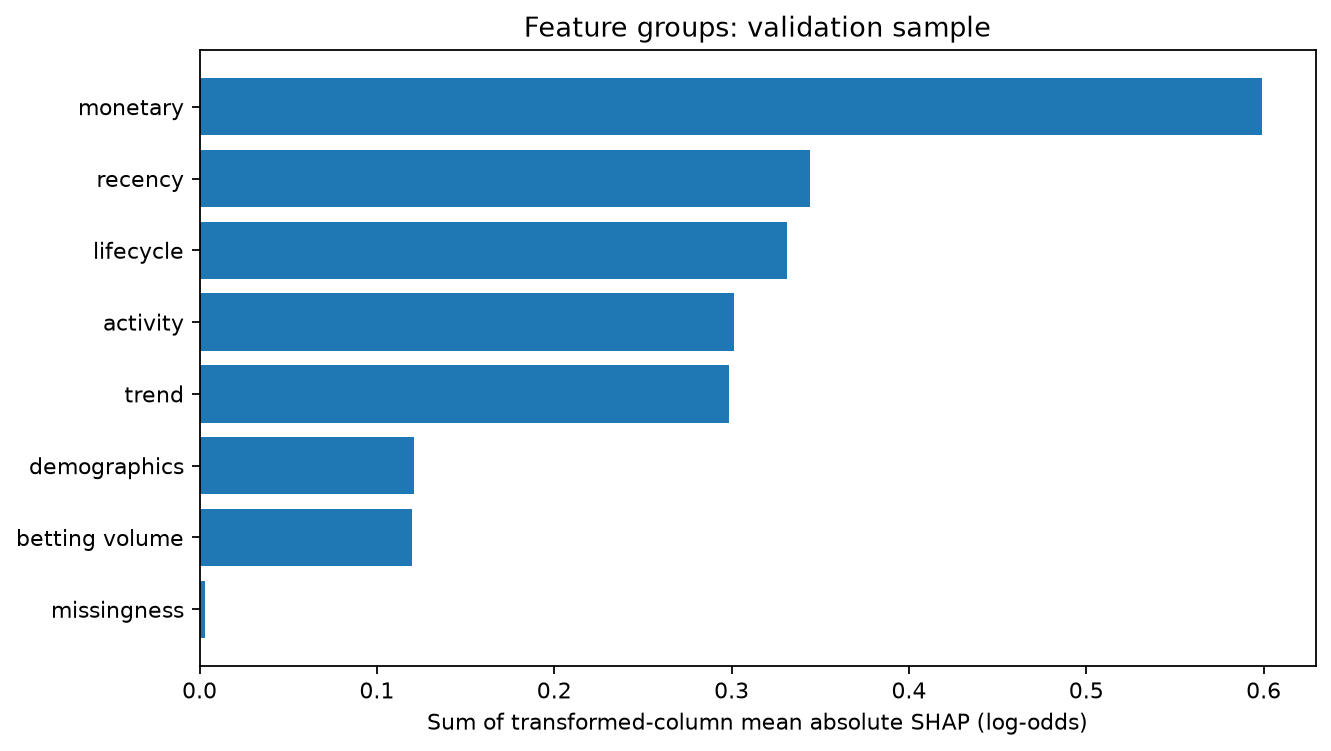

In [11]:
show_section('Feature groups')
show_figure('shap_feature_group_bar.png')

## 11. Demographic and missingness review

In [12]:
show_section('Demographics and missingness')


- **demographics**: 5.72% of summed mean absolute SHAP; highest column `Language = 2` is rank 14 (0.03672 log-odds). At least one column appears in the top 20; review its role.
- **missingness**: 0.14% of summed mean absolute SHAP; highest column `max_gap_between_active_days_30d (missing)` is rank 51 (0.00303 log-odds). No column appears in the top 20.

| feature | mean_abs_shap | shap_rank | permutation_rank |
| --- | --- | --- | --- |
| Language | 0.0448 | 12 | 32 |
| Country | 0.0326 | 16 | 14 |
| Gender | 0.0010 | 44 | 37 |

Missingness indicators with nonzero mean absolute SHAP:

| feature | mean_abs_shap | shap_rank |
| --- | --- | --- |
| max_gap_between_active_days_30d (missing) | 0.0030 | 51 |

Importance is reported neutrally: low demographic attribution does not establish fairness, and proxy effects can remain in behavioral predictors. Country/Language/Gender require governance review before operational use; this notebook performs no subgroup fairness audit or feature removal. Structural missingness may encode player behavior (for example, insufficient activity to define a gap) or source-data availability. A zero indicator attribution does not mean missingness is irrelevant: median-imputed values and correlated predictors may carry it indirectly.


## 12. Responsible interpretation

In [13]:
show_section('Responsible interpretation and limitations')


The model predicts extended inactivity: no positive-bet day in the 60 days after the snapshot. It does **not** diagnose gambling harm, identify problem gambling, determine customer value, or prove why a player churns. Model explanations describe associations used by the model, not causal behavioral explanations.

- Correlated/derived predictors make individual attributions reference-dependent; tree-path SHAP does not resolve confounding.
- Repeated-player dependence means sampled snapshots are not independent; the analysis is not evidence of unseen-player generalization.
- This historical 2005-2006 dataset may not represent current products, regulation or player populations; demographic history is not independently verified.
- Model-family selection already used validation, so performance and interpretations can have validation-selection optimism. No uncertainty intervals or causal inference are provided.
- Uniform sampling and quantile summaries can underrepresent rare categories/extremes. Local cases are illustrative, not a representative survey.
- Synthetic interaction contrasts may be outside observed joint support and do not constitute exact SHAP interaction attribution.
- Test remains sealed; probabilities remain uncalibrated; no final operational threshold was chosen.


## 13. Verification and reproducibility

Reusable tests cover transformed names, SHAP shape and finiteness, metadata exclusion, probability reconstruction, seeded sampling, signed source aggregation, anonymous local exports, targeted contrasts, and rejection of sealed/mixed dates before model access.

Run the complete suite from the repository root:

```powershell
.\venv\Scripts\python.exe -m unittest discover -s tests -v
```

No model tuning or production threshold decision follows from this notebook.

In [14]:
import hashlib
validate_local_export(pd.read_csv(ROOT / 'reports/shap_local_explanations.csv'))
assert hashlib.sha256((ROOT / 'models/xgboost_model.joblib').read_bytes()).hexdigest() == analysis['model_sha256']
metadata = pd.read_json(ROOT / 'reports/shap_run_metadata.json', typ='series')
assert not metadata['test_predictions_generated']
assert not metadata['test_shap_computed']
assert not metadata['model_refitted']
assert not metadata['final_threshold_selected']
print('Frozen model fingerprint unchanged; test remains sealed.')
print('Saved reports/shap_summary.md, 7 aggregate/anonymous CSVs, 12 PNG figures and run metadata.')

Frozen model fingerprint unchanged; test remains sealed.
Saved reports/shap_summary.md, 7 aggregate/anonymous CSVs, 12 PNG figures and run metadata.


## 14. Final explanation summary

In [15]:
display(Markdown('**Top 10 transformed SHAP features**'))
display(analysis['global_table'].head(10)[['feature', 'mean_abs_shap', 'feature_group']])
display(Markdown('**Top feature groups**'))
display(analysis['groups'].head(5))
show_section('Direction and nonlinear patterns')
show_section('Targeted interaction diagnostics')
show_section('Local explanations (diagnostic threshold 0.50)')
show_section('Consistency with Day 8 permutation importance')
show_section('Demographics and missingness')
show_section('Responsible interpretation and limitations')

**Top 10 transformed SHAP features**

,feature,mean_abs_shap,feature_group
0,days_since_last_active_bet,0.344336,recency
1,days_since_first_casino_activity,0.244612,lifecycle
2,winnings_7d,0.213860,monetary
3,active_days_30d,0.197875,activity
4,net_loss_30d,0.101938,monetary
5,net_loss_7d,0.069761,monetary
6,winnings_14d,0.063180,monetary
7,days_since_first_pay,0.060941,lifecycle
8,active_days_recent15,0.059352,trend
9,active_days_early15,0.052223,trend


**Top feature groups**

,feature_group,mean_abs_shap,share
0,monetary,0.599300,0.282881
1,recency,0.344336,0.162533
2,lifecycle,0.331489,0.156469
3,activity,0.301266,0.142203
4,trend,0.298306,0.140806



- **days_since_last_active_bet**: low observed bin [0, 1] (n=219) has mean SHAP -0.831; high bin [22, 29] (n=167) has +0.366 log-odds. Higher values have higher average contributions in this low/high comparison. Bin means are monotonic across this sample, but this does not establish a globally monotonic response.
- **active_days_30d**: low observed bin [1, 2] (n=502) has mean SHAP +0.154; high bin [9, 30] (n=158) has -0.421 log-odds. Higher values have lower average contributions in this low/high comparison. Bin means are monotonic across this sample, but this does not establish a globally monotonic response.
- **winnings_7d**: low observed bin [0, 44.6] (n=667) has mean SHAP +0.147; high bin [656, 5.72e+04] (n=167) has -0.384 log-odds. Higher values have lower average contributions in this low/high comparison. Bin means are monotonic across this sample, but this does not establish a globally monotonic response.
- **max_daily_stake_30d**: low observed bin [0, 20] (n=170) has mean SHAP +0.025; high bin [2.61e+03, 1.01e+05] (n=167) has -0.081 log-odds. Higher values have lower average contributions in this low/high comparison. Intermediate bin means reverse direction: the observed pattern is nonlinear/nonmonotonic.
- **days_since_first_casino_activity**: low observed bin [0, 149] (n=168) has mean SHAP +0.013; high bin [448, 484] (n=163) has -0.318 log-odds. Higher values have lower average contributions in this low/high comparison. Intermediate bin means reverse direction: the observed pattern is nonlinear/nonmonotonic.

These are marginal patterns in the observed validation sample, affected by other predictors and missingness. Quantile edges are descriptive bins, not learned operational thresholds. The dependence plots retain all finite values (monetary axes use a signed logarithmic scale); no cutoff or causal effect is inferred. Rows with a missing plotted value or color are excluded from that scatter; bin summaries separately record missing feature values.



| feature_1 | feature_2 | first_low | first_high | second_low | second_high | mean_mixed_margin | mean_abs_mixed_margin | fraction_nonzero | n |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| days_since_last_active_bet | active_days_30d | 2.0000 | 18.0000 | 1.0000 | 6.0000 | 0.2877 | 0.2877 | 1.0000 | 1000 |
| days_since_last_active_bet | bets_30d | 2.0000 | 18.0000 | 10.0000 | 297.2500 | -0.0000 | 0.0000 | 0.0000 | 1000 |
| active_days_30d | days_since_first_casino_activity | 1.0000 | 6.0000 | 218.0000 | 432.5000 | -0.0216 | 0.0220 | 1.0000 | 1000 |
| winnings_7d | active_days_30d | 0.0000 | 171.1465 | 1.0000 | 6.0000 | -0.1071 | 0.1073 | 1.0000 | 1000 |

These are small 2x2 fitted log-odds contrasts at each feature's validation Q25/Q75, averaged over validation sample contexts. A mixed difference is f(high,high) - f(high,low) - f(low,high) + f(low,low). A nonzero contrast supports non-additivity of the fitted function at those synthetic points; a near-zero contrast does not rule out interactions elsewhere. Positive mean contrast means the joint high/high log-odds response exceeds the sum of the two separate changes. No full interaction matrix or SHAP interaction values were computed. Dependence-plot color alone does not prove an interaction. Holding correlated and derived predictors fixed can create inconsistent/off-support combinations, so these diagnostics do not establish real-player or causal effects.



One example nearest to the within-cell median predicted probability is selected for each outcome within the SHAP sample. This is an illustrative selection rule, not a claim of population representativeness. Raw player records, identifiers, row indices, dates and local predictor values are omitted from exports. Waterfalls show anonymous feature contributions in log-odds.

| case | outcome | probability | actual | increasing_risk | decreasing_risk |
| --- | --- | --- | --- | --- | --- |
| Validation Case A | TP | 0.5729 | 1 | days_since_last_active_bet (+0.343 log-odds); winnings_7d (+0.166 log-odds); active_days_30d (+0.129 log-odds) | days_since_first_casino_activity (-0.291 log-odds); days_since_registration (-0.026 log-odds); net_loss_7d (-0.024 log-odds) |
| Validation Case B | FP | 0.5560 | 0 | days_since_last_active_bet (+0.210 log-odds); winnings_7d (+0.151 log-odds); bets_30d (+0.149 log-odds) | days_since_first_casino_activity (-0.241 log-odds); net_loss_30d (-0.152 log-odds); avg_stake_per_bet_30d (-0.045 log-odds) |
| Validation Case C | TN | 0.1996 | 0 | active_days_30d (+0.099 log-odds); net_loss_30d (+0.089 log-odds); days_since_first_pay (+0.061 log-odds) | days_since_first_casino_activity (-0.396 log-odds); winnings_7d (-0.360 log-odds); mean_gap_between_active_days_30d (-0.147 log-odds) |
| Validation Case D | FN | 0.3738 | 1 | active_days_30d (+0.271 log-odds); net_loss_7d (+0.163 log-odds); days_since_first_pay (+0.087 log-odds) | days_since_last_active_bet (-0.727 log-odds); days_since_first_casino_activity (-0.224 log-odds); avg_bets_per_active_day_7d (-0.055 log-odds) |

The same risk-increasing associations can occur in both TP/FP cases, and risk-decreasing associations in both TN/FN cases: an explanation describes the score, not why the observed outcome occurred. The 0.50 diagnostic does not select a deployment threshold.



| feature | shap_rank | permutation_rank | notes |
| --- | --- | --- | --- |
| days_since_last_active_bet | 1 | 1 | Both top 10 |
| days_since_first_casino_activity | 2 | 4 | Both top 10 |
| winnings_7d | 3 | 2 | Both top 10 |
| active_days_30d | 4 | 3 | Both top 10 |
| net_loss_30d | 5 | 15 | Different attribution/AP disruption; correlated features may redistribute importance |
| net_loss_7d | 6 | 45 | Different attribution/AP disruption; correlated features may redistribute importance |
| winnings_14d | 7 | 22 | Different attribution/AP disruption; correlated features may redistribute importance |
| days_since_first_pay | 8 | 6 | Both top 10 |
| active_days_recent15 | 9 | 8 | Both top 10 |
| active_days_early15 | 10 | 13 | Ranks within 5 positions |
| mean_gap_between_active_days_30d | 11 | 10 | Ranks within 5 positions |
| Language | 12 | 32 | Different attribution/AP disruption; correlated features may redistribute importance |
| bets_30d | 13 | 25 | Different attribution/AP disruption; correlated features may redistribute importance |
| winnings_30d | 14 | 16 | Ranks within 5 positions |
| stake_recent15 | 15 | 11 | Ranks within 5 positions |
| Country | 16 | 14 | Ranks within 5 positions |
| max_daily_stake_30d | 17 | 5 | Different attribution/AP disruption; correlated features may redistribute importance |
| avg_bets_per_active_day_30d | 18 | 44 | Different attribution/AP disruption; correlated features may redistribute importance |
| active_days_7d_share | 19 | 31 | Different attribution/AP disruption; correlated features may redistribute importance |
| avg_bets_per_active_day_7d | 20 | 20 | Ranks within 5 positions |

Top-10 overlap: 6/10; source-level Spearman rank correlation 0.626. The five earlier drivers have SHAP source ranks: days_since_last_active_bet 1, winnings_7d 3, active_days_30d 4, days_since_first_casino_activity 2, max_daily_stake_30d 17.

SHAP partly challenges the earlier ordering; inspect the source ranks above.

For comparability, signed SHAP contributions of every raw feature's descendants (including its missing indicator and category levels) are summed within each row, then absolute-valued and averaged. This differs from the transformed/group tables. Permutation importance measures full-validation average-precision loss after shuffling a raw predictor (five repeats); SHAP measures contribution magnitude in a 1,000-row sample. Correlated predictors can share SHAP credit; permutation can disrupt correlated structure, and nonlinear interactions redistribute contributions. Small negative AP drops reflect noise/redundancy, not protective effects. Neither ranking is absolute truth.



- **demographics**: 5.72% of summed mean absolute SHAP; highest column `Language = 2` is rank 14 (0.03672 log-odds). At least one column appears in the top 20; review its role.
- **missingness**: 0.14% of summed mean absolute SHAP; highest column `max_gap_between_active_days_30d (missing)` is rank 51 (0.00303 log-odds). No column appears in the top 20.

| feature | mean_abs_shap | shap_rank | permutation_rank |
| --- | --- | --- | --- |
| Language | 0.0448 | 12 | 32 |
| Country | 0.0326 | 16 | 14 |
| Gender | 0.0010 | 44 | 37 |

Missingness indicators with nonzero mean absolute SHAP:

| feature | mean_abs_shap | shap_rank |
| --- | --- | --- |
| max_gap_between_active_days_30d (missing) | 0.0030 | 51 |

Importance is reported neutrally: low demographic attribution does not establish fairness, and proxy effects can remain in behavioral predictors. Country/Language/Gender require governance review before operational use; this notebook performs no subgroup fairness audit or feature removal. Structural missingness may encode player behavior (for example, insufficient activity to define a gap) or source-data availability. A zero indicator attribution does not mean missingness is irrelevant: median-imputed values and correlated predictors may carry it indirectly.



The model predicts extended inactivity: no positive-bet day in the 60 days after the snapshot. It does **not** diagnose gambling harm, identify problem gambling, determine customer value, or prove why a player churns. Model explanations describe associations used by the model, not causal behavioral explanations.

- Correlated/derived predictors make individual attributions reference-dependent; tree-path SHAP does not resolve confounding.
- Repeated-player dependence means sampled snapshots are not independent; the analysis is not evidence of unseen-player generalization.
- This historical 2005-2006 dataset may not represent current products, regulation or player populations; demographic history is not independently verified.
- Model-family selection already used validation, so performance and interpretations can have validation-selection optimism. No uncertainty intervals or causal inference are provided.
- Uniform sampling and quantile summaries can underrepresent rare categories/extremes. Local cases are illustrative, not a representative survey.
- Synthetic interaction contrasts may be outside observed joint support and do not constitute exact SHAP interaction attribution.
- Test remains sealed; probabilities remain uncalibrated; no final operational threshold was chosen.
